# Moment reproduction per statistic

For each statistic $k$, with $m_k$ = mean on the data x1 ($n$ windows) and $\hat m_k$ = mean on the model samples ($n_s$):

- **offset** $=\sqrt{e_k} = |m_k-\hat m_k| / \mathrm{std}_{data,k}$: how far the model's mean is, in standard deviations of the data (not a % of the mean). Reading: < 0.05 very good, 0.05–0.2 small shift, 0.2–0.5 clear shift, > 0.5 big miss.
- **noise** $=\sqrt{(s^2_{data}/n + s^2_{model}/n_s)}/\mathrm{std}_{data}$: the offset expected from finite samples alone (≈ 0.014 at $n=n_s=10^4$ for well-behaved statistics, much larger for heavy-tailed ones).
- **Verdict** of each statistic (heatmap):
  - **grey = matched**: offset ≤ 2 × noise, and 2 × noise < 0.05, so the measurement is sharp enough to call it a match;
  - **hatched = can't tell**: offset ≤ 2 × noise, but the noise is too large to judge;
  - **colour = miss**: the offset, fixed log scale 0.01 to 1.
- **rel_mean** $=(\hat m_k-m_k)/|m_k|$: percentage error, in the table only, where the mean is clearly away from 0.

Imposed (dot) = the run's own potentials (config.json + fitted_potentials/, never refitted). Extra = chosen in the ⚠ cell. First seed of each label. Run on Jean Zay. Models are grouped by dataset: rows of one heatmap share M, J, Q. Thresholds: `NOISE_K`, `RESOLVED_MAX`, `REL_MEAN_MIN`, `OFFSET_RANGE` at the top of `moment_reproduction.py`.

In [2]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'moment_reproduction'))
import numpy as np
from moment_reproduction import load_model, compute_moment_reproduction, plot_summary, plot_strip, DEVICE
%matplotlib inline

In [3]:
# ── MODELS ── group -> {row name: (results root, --label of the run)}. Every statistic a model imposes
# is always checked (loaded with its saved fit, never refitted).
# Turbulence rows: mass_final = M3 + Scat4; M3 = unconstrained windows; A = windows >= step noise;
# B = A + mass of every window. GGD columns are aligned by (channel, window) label, but M3/mass_final
# windows differ from A/B windows: same label != same window across those two pairs.
GROUPS = {
    # 'turbulence (M=256, J=8, Q=3)': {
    #     #'full (Scat4)':      (ROOT / 'turbulence', 'turbulence_ggd_mass_final'),
    #     #'M3':                (ROOT / 'turbulence', 'turbulence_nested_M3'),
    #     #'A (bicw)':          (ROOT / 'turbulence', 'turbulence_nested_M3_bicw'),
    #     #'B (bicw_allmass)':  (ROOT / 'turbulence', 'turbulence_nested_M3_bicw_allmass'),
    #     'C (bicw_rich)':     (ROOT / 'turbulence', 'turbulence_nested_M3_bicw_rich'),
    #     'B + Scat4':         (ROOT / 'turbulence', 'turbulence_nested_M3_bicw_allmass_scat4'),
    # },
    'jets (M=256, J=8, Q=1)': {
        'jets full':                  (ROOT / 'jets', 'jets_full'),
        'no scalar':                  (ROOT / 'jets', 'jets_noscalar'),
        'no Scat3/4':                 (ROOT / 'jets', 'jets_scat2_scalar'),
        'no Scat3/4, no scalar':      (ROOT / 'jets', 'jets_scat2'),
    },
}

## ⚠ CHOOSE THE EXTRA STATISTICS HERE

The **imposed** statistics of each model are always checked, with no choice needed. `EXTRA` lists the **additional, non-imposed** families evaluated on every model of a group. A family that a model imposes stays imposed for that model, using its own fit (matched by family name). The same extra family is a *test* for the models that don't impose it.

- Scattering / L_p extras: no fit, same definition for every model.
- `Scalar_*` extras (GGD): windows **fitted once on the data x1** (final-model settings, `EXTRA_GGD` in `moment_reproduction.py`), saved in `moment_reproduction/cache/`, and reused for every model with the same x1.
- Not caught automatically: two families with different names computing the same numbers. For example, with Q=1 (jets) `Scalar_psi` runs on the same bank as `Scalar_morlet`.

In [20]:
# ── EXTRA (non-imposed) STATISTICS ── edit this list only; one per line, with why it is here.
EXTRA = [
    'L_6',                                      # 6th-order marginal moment (imposed by most turbulence models)
    'Scattering_First_Order',                   # E|W x| per channel
    'Scattering_Second_Order',                  # E|W |W x||: scale-to-scale envelope
    'Scattering_Third_Order_Real',              # cross-scale phase (Q=3 bank, as the code does)
    'Scattering_Third_Order_Imag',
    'Scattering_Fourth_Order_Mod2_Real_Q1',     # the Scat4 mass_final IMPOSES: test for M3 / A / B
    'Scattering_Fourth_Order_Mod2_Imag_Q1',
    'Scalar_morlet_gaussianK',                  # marginals Q=1 bank (imposed by all turbulence models)
    'Scalar_psi_gaussianK',                     # marginals Q=3 bank (imposed by all turbulence models)
    'Scalar_morlet_gaussianK_imag',             # marginals of the imaginary parts: fitted here (not imposed)
    'Scalar_psi_gaussianK_imag',
]
print(f'device: {DEVICE}')

device: cuda


In [ ]:
# RECOMPUTE = False: load the results of run_moment_reproduction.py (SLURM, one .pkl per model in results/);
# models without a .pkl are listed and skipped. True: recompute here, model by model (slow: extra GGD fits).
RECOMPUTE = False
if not RECOMPUTE:
    from run_moment_reproduction import load_results
    results, excluded = load_results(GROUPS)
else:
    import time
    results, excluded = {}, {}
    for group, models in GROUPS.items():
        results[group], shapes = {}, set()
        for name, (root, label) in models.items():
            t0 = time.time()
            cfg, pots, x1, xs = load_model(label, root)
            shapes.add((cfg['M'], cfg['J'], cfg['Q']))
            extra = [f for f in EXTRA if f not in pots]
            print(f'\n{name}: {cfg["config_name"]}  n={len(x1)} n_s={len(xs)}\n  imposed: {list(pots)}\n  extra:   {extra}')
            results[group][name], excluded[name] = compute_moment_reproduction(pots, x1, xs, EXTRA, cfg)
            print(f'  excluded (zero variance on data): {list(excluded[name].label)}  ({time.time() - t0:.0f} s)')
        assert len(shapes) == 1, f'{group}: models with different (M, J, Q) {shapes}: split the group'

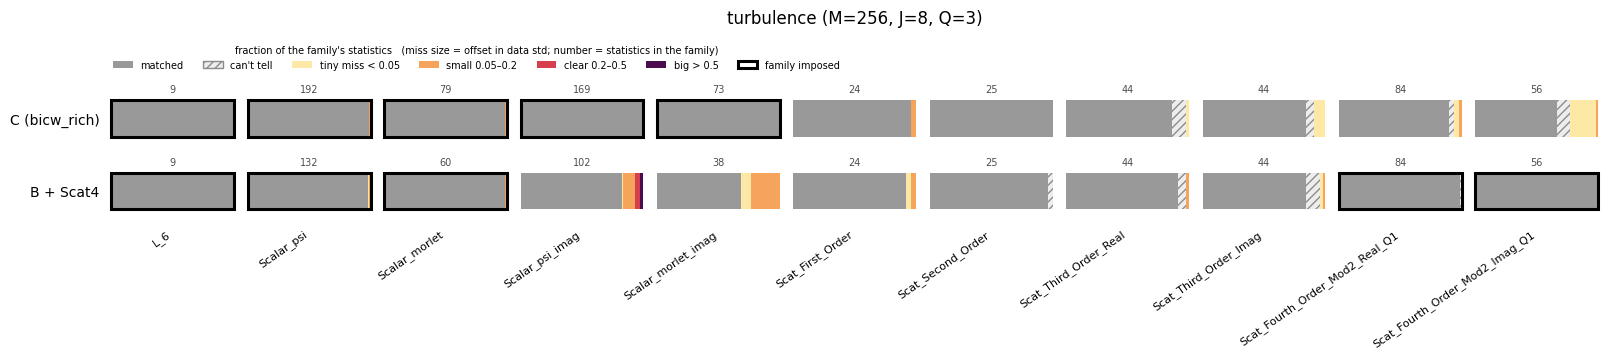

In [17]:
# Overview: one cell per (model, family) = fraction of that family's statistics matched / can't tell /
# missed by size. Thick frame = family imposed by the model. Details per statistic: strip plots below.
for group, res in results.items():
    plot_summary(res, title=group)

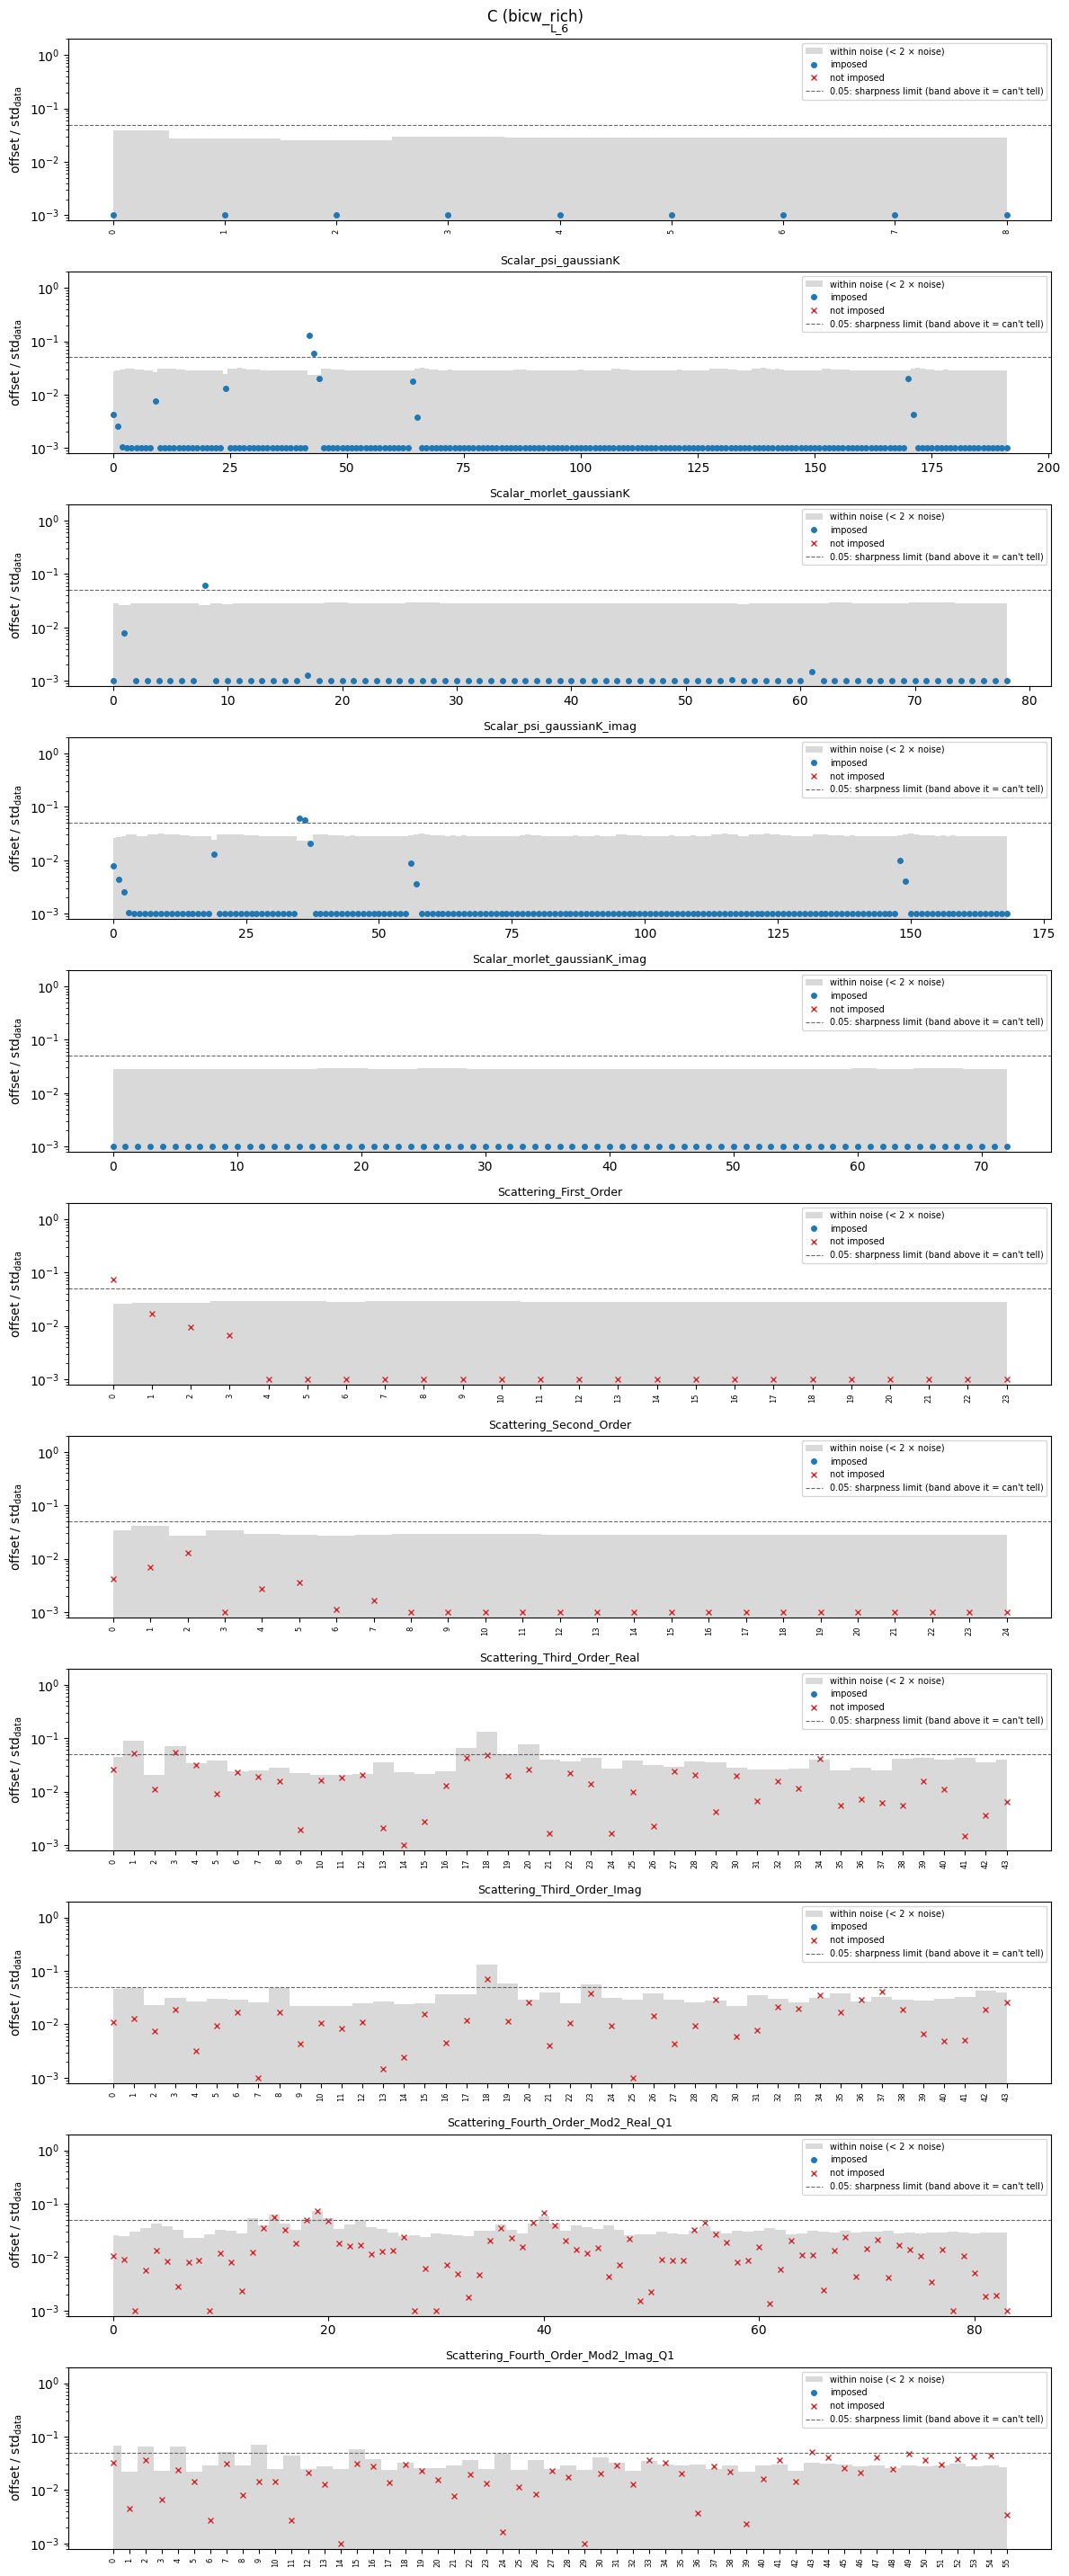

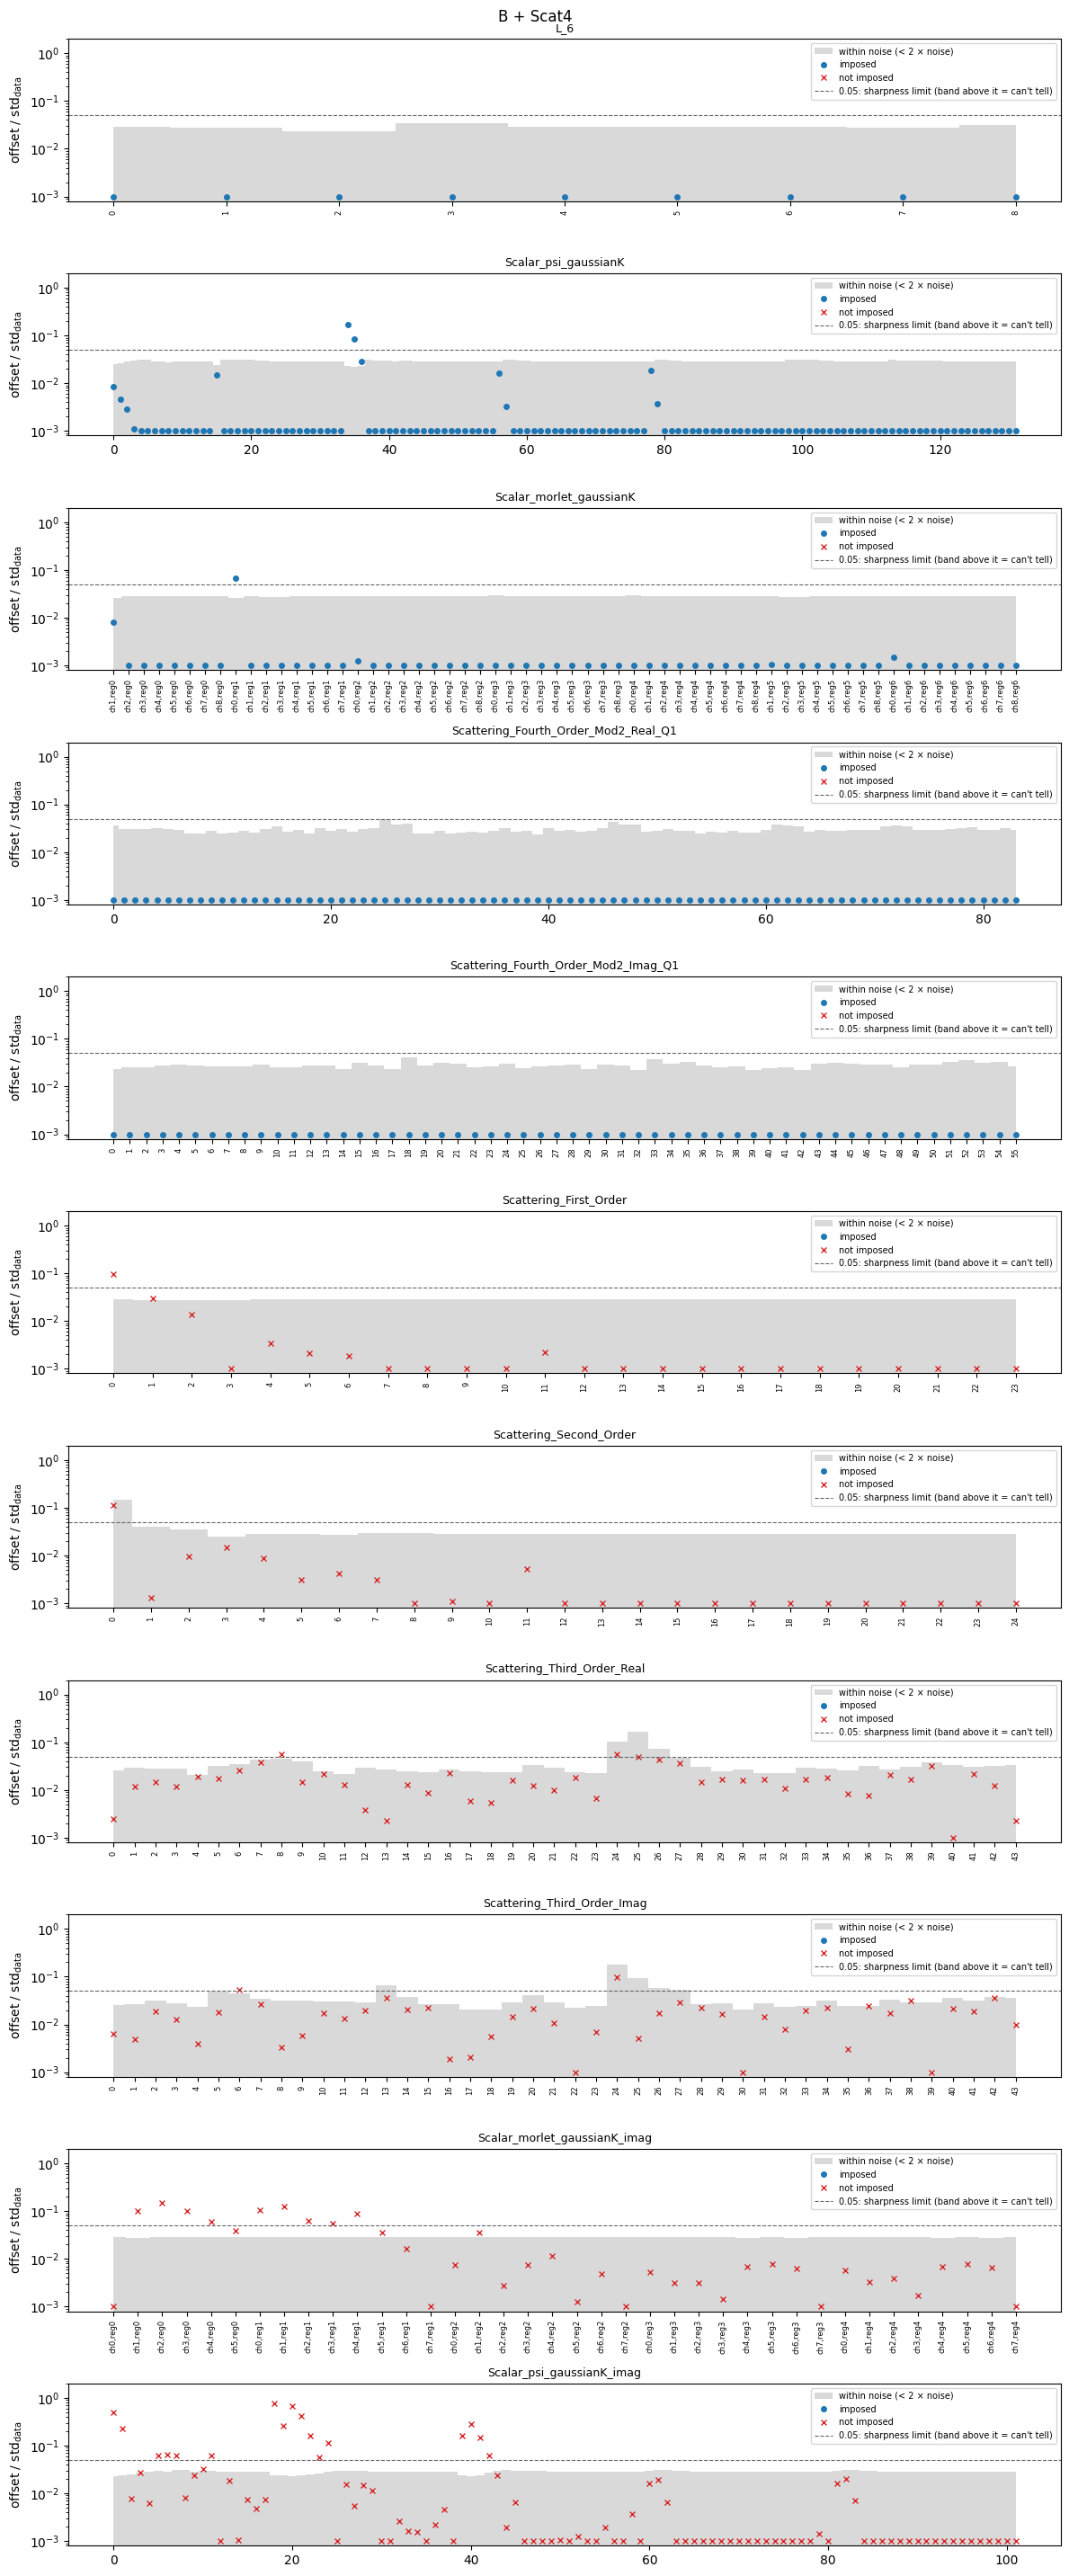

In [18]:
for group, res in results.items():
    for name, df in res.items():
        plot_strip(df).suptitle(name, y=1.0)

In [13]:
# Table per model and family. offset = |m - mhat| / std_data. Verdict per statistic:
#   matched = within 2 x noise AND 2 x noise < 0.05 (sharp);  can't tell = within noise but noise too large;
#   miss = outside noise.  rel_mean = (mhat - m)/|m| in %, only where |m| >= 0.5 std_data (else blank).
import pandas as pd
pd.set_option('display.float_format', '{:.3g}'.format)
for group, res in results.items():
    for name, df in res.items():
        print(f'\n== {name}')
        g = df.groupby(['imposed', 'family'])
        display(pd.DataFrame({
            'n':                   g.size(),
            'matched %':           100 * g['verdict'].apply(lambda s: (s == 'matched').mean()),
            "can't tell %":        100 * g['verdict'].apply(lambda s: (s == 'unresolved').mean()),
            'miss %':              100 * g['verdict'].apply(lambda s: (s == 'miss').mean()),
            'offset median':       g['offset'].median(),
            'offset max':          g['offset'].max(),
            '|rel_mean| median %': 100 * g['rel_mean'].apply(lambda s: s.abs().median()),
            'rel_mean shown':      g['rel_mean'].count(),
        }))
        big = df[df.offset > 0.1].sort_values('offset', ascending=False)
        print(f'offset > 0.1 std_data: {len(big)} statistics (top 30)')
        display(big[['family', 'label', 'imposed', 'verdict', 'offset', 'noise', 'rel_mean']].head(30))


== C (bicw_rich)


n  matched %  can't tell %  \
imposed family                                                               
False   Scattering_First_Order                 24       95.8             0   
        Scattering_Fourth_Order_Mod2_Imag_Q1   56       66.1          10.7   
        Scattering_Fourth_Order_Mod2_Real_Q1   84       89.3          4.76   
        Scattering_Second_Order                25        100             0   
        Scattering_Third_Order_Imag            44       84.1          6.82   
        Scattering_Third_Order_Real            44       86.4          11.4   
True    L_6                                     9        100             0   
        Scalar_morlet_gaussianK                79       98.7             0   
        Scalar_morlet_gaussianK_imag           73        100             0   
        Scalar_psi_gaussianK                  192         99             0   
        Scalar_psi_gaussianK_imag             169       98.8             0   

                                              miss %  offset median  \
imposed family                                                        
False   Scattering_First_Order                  4.17       4.92e-05   
        Scattering_Fourth_Order_Mod2_Imag_Q1    23.2         0.0208   
        Scattering_Fourth_Order_Mod2_Real_Q1    5.95         0.0114   
        Scattering_Second_Order                    0       0.000182   
        Scattering_Third_Order_Imag             9.09          0.011   
        Scattering_Third_Order_Real             2.27         0.0133   
True    L_6                                        0       8.73e-07   
        Scalar_morlet_gaussianK                 1.27        8.1e-07   
        Scalar_morlet_gaussianK_imag               0        1.2e-06   
        Scalar_psi_gaussianK                    1.04       1.72e-06   
        Scalar_psi_gaussianK_imag               1.18       2.38e-06   

                                              offset max  |rel_mean| median %  \
imposed family                                                                  
False   Scattering_First_Order                    0.0728              0.00514   
        Scattering_Fourth_Order_Mod2_Imag_Q1      0.0507                  NaN   
        Scattering_Fourth_Order_Mod2_Real_Q1      0.0746                  NaN   
        Scattering_Second_Order                    0.013              0.00299   
        Scattering_Third_Order_Imag                0.071                  NaN   
        Scattering_Third_Order_Real               0.0531                  NaN   
True    L_6                                     6.78e-06                  NaN   
        Scalar_morlet_gaussianK                   0.0612             8.33e-05   
        Scalar_morlet_gaussianK_imag            0.000306             0.000185   
        Scalar_psi_gaussianK                        0.13             0.000254   
        Scalar_psi_gaussianK_imag                 0.0603             0.000463   

                                              rel_mean shown  
imposed family                                                
False   Scattering_First_Order                            24  
        Scattering_Fourth_Order_Mod2_Imag_Q1               0  
        Scattering_Fourth_Order_Mod2_Real_Q1               0  
        Scattering_Second_Order                           14  
        Scattering_Third_Order_Imag                        0  
        Scattering_Third_Order_Real                        0  
True    L_6                                                0  
        Scalar_morlet_gaussianK                           46  
        Scalar_morlet_gaussianK_imag                      46  
        Scalar_psi_gaussianK                             117  
        Scalar_psi_gaussianK_imag                         98

offset > 0.1 std_data: 1 statistics (top 30)


,family,label,imposed,verdict,offset,noise,rel_mean
51,Scalar_psi_gaussianK,"Scalar_psi_gaussianK[ch0,reg3]",True,miss,0.13,0.0117,0.0439
